# Analisis Risiko Gangguan Pernapasan
## Kualitas Udara, Meteorologi, dan Mobilitas Perkotaan di Indonesia
### PRINT Group 3org — PRINT 2026

Semua temuan bersifat **asosiasi statistik**, bukan hubungan sebab-akibat.

In [1]:
import glob, io, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)

## 1. Muat Data & Cek Awal

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [n for n in uploaded if n.lower().endswith('.csv')]
    FILE = csv_files[0]
    df_raw = pd.read_csv(io.BytesIO(uploaded[FILE]))
    import io
except ImportError:
    import glob
    candidates = (
        glob.glob('/kaggle/input/**/*.csv', recursive=True) +
        glob.glob('*.csv') + glob.glob('../*.csv') +
        glob.glob(os.path.expanduser('~/Downloads/*air_quality_health*.csv'))
    )
    preferred = [p for p in candidates if 'air_quality_health' in os.path.basename(p)]
    FILE = preferred[0] if preferred else candidates[0]
    df_raw = pd.read_csv(FILE)

df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp'])
print(f"File: {os.path.basename(FILE)}")
print(f"Shape: {df_raw.shape}")
print(f"Duplikat baris: {df_raw.duplicated().sum()}")
print(f"Duplikat record_id: {df_raw['record_id'].duplicated().sum()}")
print(f"Rentang: {df_raw['timestamp'].min().date()} s.d. {df_raw['timestamp'].max().date()}")
print(f"Kota: {sorted(df_raw['city'].unique())}")
df_raw.head()

File: indonesia_air_quality_health (2).csv
Shape: (5000, 12)
Duplikat baris: 0
Duplikat record_id: 0
Rentang: 2026-08-25 s.d. 2026-10-26
Kota: ['Bandung', 'Bekasi', 'Depok', 'Jakarta Pusat', 'Makassar', 'Medan', 'Palembang', 'Semarang', 'Surabaya', 'Tangerang']


,record_id,timestamp,city,zone_type,temperature_c,rainfall_mm,traffic_index,pm25_ug_m3,no2_ppb,aqi_score,air_quality_status,respiratory_cases
0,AQI-10000,2026-08-25,Jakarta Pusat,Traffic,24.7,0.0,59.9,76.2,72.2,103,Unhealthy for Sensitive Groups,80
1,AQI-10001,2026-08-25,Bekasi,Industrial,27.9,0.8,39.6,60.0,50.3,81,Moderate,57
2,AQI-10002,2026-08-25,Tangerang,Industrial,26.3,0.0,64.9,92.7,74.4,125,Unhealthy for Sensitive Groups,75
3,AQI-10003,2026-08-25,Depok,Residential,25.1,0.0,36.9,47.5,36.7,64,Moderate,39
4,AQI-10004,2026-08-25,Bandung,Traffic,26.9,0.0,74.6,46.2,65.6,82,Moderate,58


## 2. Cleaning Data
- Imputasi missing value menggunakan **median per kota** (bukan median global).
- Outlier IQR dilaporkan namun tidak dibuang. Nilai 0 pada `rainfall_mm` dipertahankan.

In [3]:
df = df_raw.copy()
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 2a. Missing
print("=== Missing per Kolom ===")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 2b. Sebaran missing per kota
cols_impute = ['temperature_c', 'traffic_index', 'pm25_ug_m3']
for col in cols_impute:
    print(f"\n{col}:")
    print(df[df[col].isnull()].groupby('city').size())

# 2c. Imputasi median per kota
for col in cols_impute:
    df[col] = df.groupby('city')[col].transform(lambda x: x.fillna(x.median()))
print("\nVerifikasi setelah imputasi:")
print(df[cols_impute].isnull().sum())

# 2d. Outlier IQR
print("\n=== Outlier IQR (dipertahankan) ===")
for col in ['temperature_c','rainfall_mm','traffic_index','pm25_ug_m3','no2_ppb','aqi_score','respiratory_cases']:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    n_out = ((df[col] < Q1-1.5*(Q3-Q1)) | (df[col] > Q3+1.5*(Q3-Q1))).sum()
    print(f"  {col}: {n_out} outlier")

# 2e. Crosstab
print("\n=== Crosstab City x Zone ===")
print(pd.crosstab(df['city'], df['zone_type']))
print("Catatan: Setiap kota hanya memiliki satu tipe zona.")

=== Missing per Kolom ===
temperature_c    50
traffic_index    50
pm25_ug_m3       50
dtype: int64

temperature_c:
city
Bandung          6
Bekasi           4
Depok            4
Jakarta Pusat    6
Makassar         4
Medan            6
Palembang        4
Semarang         7
Surabaya         4
Tangerang        5
dtype: int64

traffic_index:
city
Bandung          4
Bekasi           5
Depok            8
Jakarta Pusat    4
Makassar         4
Medan            4
Palembang        7
Semarang         3
Surabaya         3
Tangerang        8
dtype: int64

pm25_ug_m3:
city
Bandung          4
Bekasi           4
Depok            3
Jakarta Pusat    2
Makassar         6
Medan            3
Palembang        7
Semarang         7
Surabaya         6
Tangerang        8
dtype: int64

Verifikasi setelah imputasi:
temperature_c    0
traffic_index    0
pm25_ug_m3       0
dtype: int64

=== Outlier IQR (dipertahankan) ===
  temperature_c: 0 outlier
  rainfall_mm: 868 outlier
  traffic_index: 0 outlier
  pm25_ug_m3: 

## 3. Variabel Turunan

In [4]:
df['risk_aqi']      = df['aqi_score'] > 100
df['hour']          = df['timestamp'].dt.hour
df['is_weekend']    = df['timestamp'].dt.dayofweek >= 5
df['rain_category'] = df['rainfall_mm'] > 0
print(f"risk_aqi: {df['risk_aqi'].sum()} baris ({df['risk_aqi'].mean()*100:.2f}%)")
print(f"Weekend: {df['is_weekend'].sum()} | Weekday: {(~df['is_weekend']).sum()}")
print(f"Hujan: {df['rain_category'].sum()} | Tidak: {(~df['rain_category']).sum()}")

risk_aqi: 1071 baris (21.42%)
Weekend: 1440 | Weekday: 3560
Hujan: 868 | Tidak: 4132


## 4. Analisis Spasial

In [5]:
kota_tbl = df.groupby('city').agg(
    AQI=('aqi_score','mean'), PM25=('pm25_ug_m3','mean'),
    NO2=('no2_ppb','mean'),   Kasus=('respiratory_cases','mean')
).round(2).sort_values('AQI', ascending=False)

zona_tbl = df.groupby('zone_type').agg(
    AQI=('aqi_score','mean'), PM25=('pm25_ug_m3','mean'),
    NO2=('no2_ppb','mean'),   Kasus=('respiratory_cases','mean')
).round(2)

print("=== Rerata per Kota ==="); print(kota_tbl)
print("\n=== Rerata per Zona ==="); print(zona_tbl)
print("\n=== Kota Zona Traffic (Jakarta Pusat, Bandung, Medan) ===")
print(kota_tbl.loc[['Jakarta Pusat','Bandung','Medan']])

=== Rerata per Kota ===
                 AQI   PM25    NO2  Kasus
city                                     
Jakarta Pusat  97.23  62.37  76.80  83.02
Bekasi         93.48  68.26  64.69  69.42
Bandung        91.63  58.52  72.36  71.39
Medan          90.22  60.96  69.94  59.77
Tangerang      88.87  64.30  62.65  63.93
Surabaya       87.78  62.07  65.49  66.24
Semarang       78.81  55.52  57.83  46.52
Palembang      78.78  57.94  48.91  44.28
Depok          68.83  46.87  51.37  46.64
Makassar       62.39  40.92  46.55  35.02

=== Rerata per Zona ===
               AQI   PM25    NO2  Kasus
zone_type                              
Industrial   87.23  62.54  62.66  61.52
Residential  70.00  48.58  48.94  41.98
Traffic      93.03  60.62  73.03  71.39

=== Kota Zona Traffic (Jakarta Pusat, Bandung, Medan) ===
                 AQI   PM25    NO2  Kasus
city                                     
Jakarta Pusat  97.23  62.37  76.80  83.02
Bandung        91.63  58.52  72.36  71.39
Medan          90.22

## 5. Analisis Temporal

In [6]:
jam_tbl = df.groupby('hour').agg(
    traffic=('traffic_index','mean'), AQI=('aqi_score','mean'),
    kasus=('respiratory_cases','mean')
).round(2)

def pct_risk(x): return (x > 100).mean() * 100
wd_we = df.groupby('is_weekend').agg(
    traffic=('traffic_index','mean'), PM25=('pm25_ug_m3','mean'),
    NO2=('no2_ppb','mean'), AQI=('aqi_score','mean'),
    kasus=('respiratory_cases','mean'), pct_AQI_risk=('aqi_score', pct_risk)
).round(2)
wd_we.index = ['Weekday','Weekend']
print("=== Rerata per Jam ==="); print(jam_tbl)
print("\n=== Weekday vs Weekend ==="); print(wd_we)

=== Rerata per Jam ===
      traffic    AQI  kasus
hour                       
0       45.92  79.23  56.87
3       45.94  79.57  57.41
6       65.57  91.08  63.07
9       65.70  91.09  61.07
12      45.46  79.85  54.99
15      45.99  78.61  54.25
18      64.91  90.82  63.30
21      45.90  80.07  57.98

=== Weekday vs Weekend ===
         traffic   PM25    NO2    AQI  kasus  pct_AQI_risk
Weekday    60.20  60.22  65.53  87.85  60.79         28.43
Weekend    35.88  51.71  52.08  73.79  53.27          4.10


## 6. Hujan & Cuaca

In [7]:
hujan_tbl = df.groupby('rain_category').agg(
    PM25=('pm25_ug_m3','mean'), AQI=('aqi_score','mean'), kasus=('respiratory_cases','mean')
).round(2)
hujan_tbl.index = ['Tidak Hujan','Hujan']
print("=== Hujan vs Tidak Hujan ==="); print(hujan_tbl)

rho_rain_pm25, _ = stats.spearmanr(df['rainfall_mm'], df['pm25_ug_m3'])
rho_rain_aqi,  _ = stats.spearmanr(df['rainfall_mm'], df['aqi_score'])
rho_temp_aqi,  _ = stats.spearmanr(df['temperature_c'], df['aqi_score'])
rho_temp_cas,  _ = stats.spearmanr(df['temperature_c'], df['respiratory_cases'])
print(f"rho rainfall-PM2.5={rho_rain_pm25:.3f}  rainfall-AQI={rho_rain_aqi:.3f}")
print(f"rho suhu-AQI={rho_temp_aqi:.3f}  suhu-kasus={rho_temp_cas:.3f}")

=== Hujan vs Tidak Hujan ===
              PM25    AQI  kasus
Tidak Hujan  60.54  87.69  60.75
Hujan        44.61  65.30  48.52
rho rainfall-PM2.5=-0.405  rainfall-AQI=-0.413
rho suhu-AQI=-0.017  suhu-kasus=-0.098


## 7. Uji Statistik & Korelasi

In [8]:
from scipy import stats as _stats
safe  = df[~df['risk_aqi']]['respiratory_cases']
risky = df[ df['risk_aqi']]['respiratory_cases']
_, mw_p = _stats.mannwhitneyu(safe, risky, alternative='two-sided')
print(f"Mann-Whitney AQI aman vs berisiko: {safe.mean():.2f} vs {risky.mean():.2f}, p={mw_p:.3e}")

groups_zona = [g['respiratory_cases'].values for _,g in df.groupby('zone_type')]
_, kw_p = _stats.kruskal(*groups_zona)
print(f"Kruskal-Wallis antar zona: p={kw_p:.3e}")

wd_cas = df[~df['is_weekend']]['respiratory_cases']
we_cas = df[ df['is_weekend']]['respiratory_cases']
_, p_cas = _stats.mannwhitneyu(wd_cas, we_cas, alternative='two-sided')
_, p_aqi = _stats.mannwhitneyu(df[~df['is_weekend']]['aqi_score'],
                                df[ df['is_weekend']]['aqi_score'], alternative='two-sided')
print(f"Mann-Whitney AQI weekday vs weekend: p={p_aqi:.3e}")
print(f"Mann-Whitney kasus weekday vs weekend: p={p_cas:.3e}")

rho_dict = {}
print("\n=== Spearman vs respiratory_cases ===")
for col in ['aqi_score','no2_ppb','pm25_ug_m3','traffic_index','rainfall_mm','temperature_c']:
    r, p = _stats.spearmanr(df[col], df['respiratory_cases'])
    rho_dict[col] = r
    print(f"  {col:20s}: rho={r:.3f}, p={p:.3e}")
rho_tr_no2, _ = _stats.spearmanr(df['traffic_index'], df['no2_ppb'])
print(f"  traffic vs no2        : rho={rho_tr_no2:.3f}")

Mann-Whitney AQI aman vs berisiko: 52.82 vs 79.91, p=0.000e+00
Kruskal-Wallis antar zona: p=0.000e+00
Mann-Whitney AQI weekday vs weekend: p=2.514e-99
Mann-Whitney kasus weekday vs weekend: p=8.111e-35

=== Spearman vs respiratory_cases ===
  aqi_score           : rho=0.811, p=0.000e+00
  no2_ppb             : rho=0.779, p=0.000e+00
  pm25_ug_m3          : rho=0.719, p=0.000e+00
  traffic_index       : rho=0.464, p=8.332e-266
  rainfall_mm         : rho=-0.265, p=2.258e-81
  temperature_c       : rho=-0.098, p=4.860e-12
  traffic vs no2        : rho=0.662


## 8. Analisis Lag
Shift AQI dilakukan **di dalam groupby city** agar tidak terjadi lompatan data antar kota.

In [9]:
df_s = df.sort_values(['city','timestamp']).copy()
lag_res = {}
print("=== Lag AQI (per kota) → kasus ===")
for lag in [0,1,2,4]:
    aqi_lag = df_s['aqi_score'] if lag==0 else df_s.groupby('city')['aqi_score'].shift(lag)
    mask = aqi_lag.notna()
    r, p = stats.spearmanr(aqi_lag[mask], df_s.loc[mask,'respiratory_cases'])
    lag_res[lag] = r
    print(f"  Lag {lag} ({lag*3} jam): rho={r:.3f}, n={mask.sum()}, p={p:.3e}")

=== Lag AQI (per kota) → kasus ===
  Lag 0 (0 jam): rho=0.811, n=5000, p=0.000e+00
  Lag 1 (3 jam): rho=0.422, n=4990, p=4.270e-215
  Lag 2 (6 jam): rho=0.384, n=4980, p=4.754e-175
  Lag 4 (12 jam): rho=0.428, n=4960, p=1.908e-220


## 9. Visualisasi

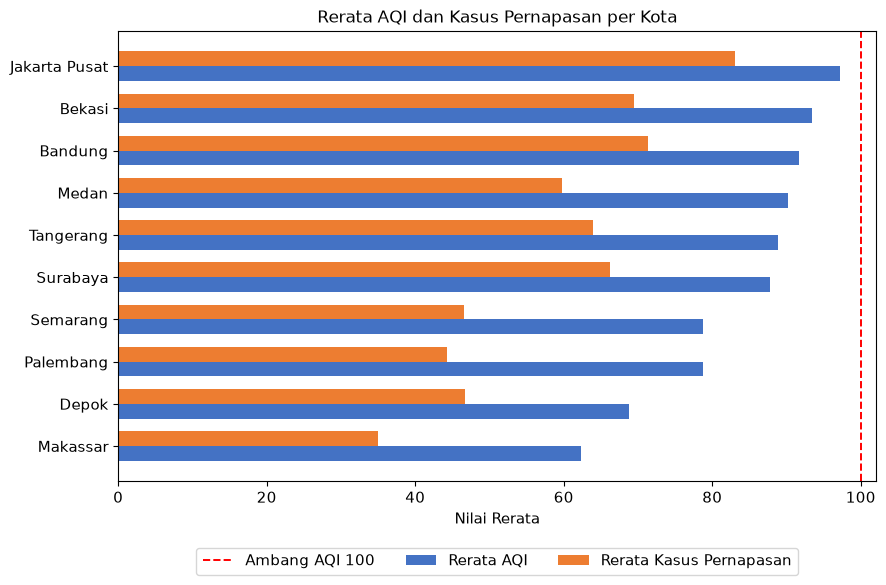

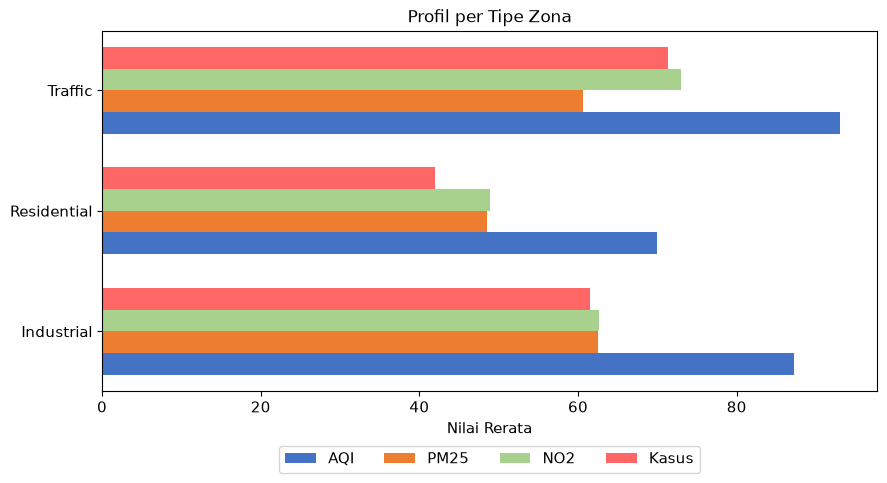

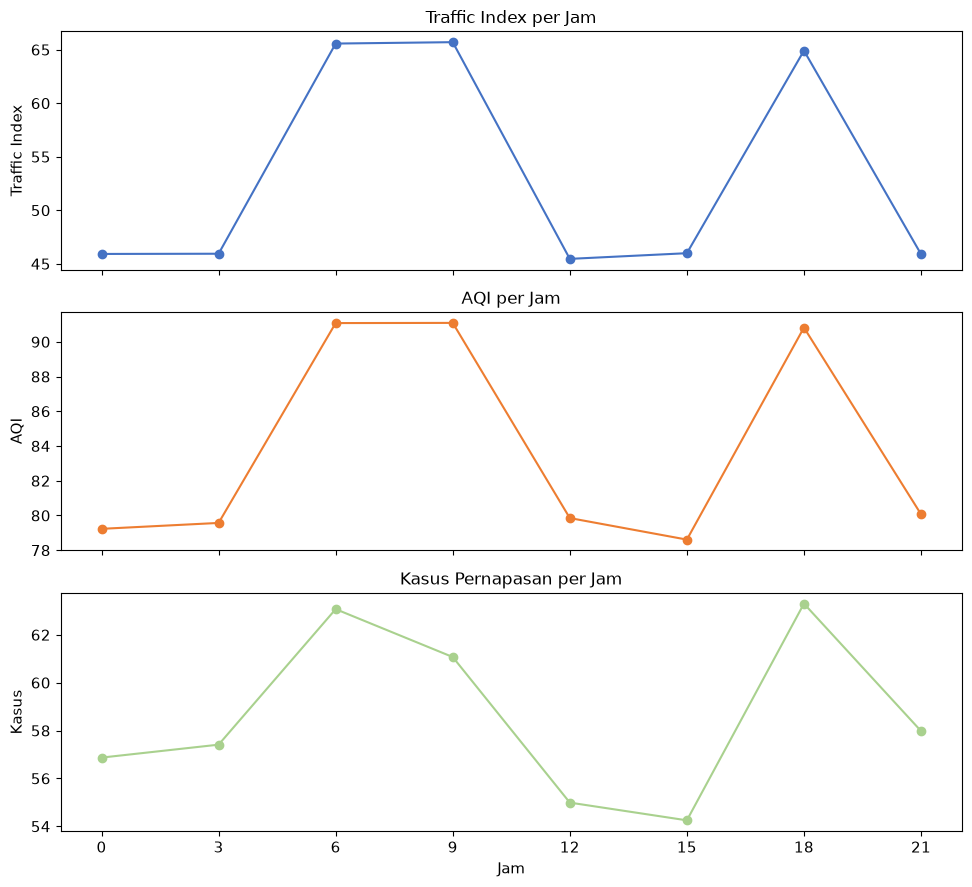

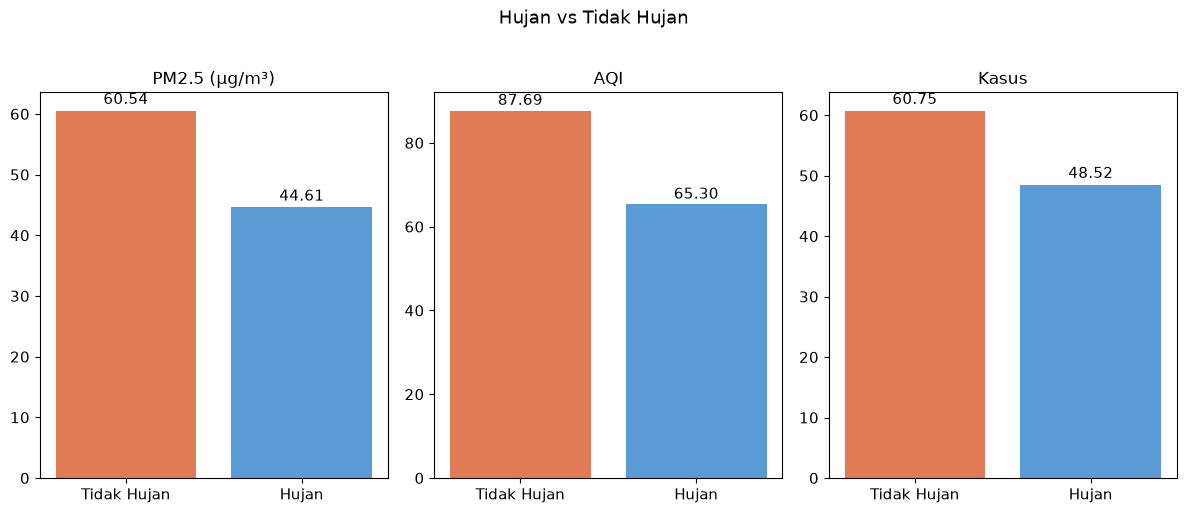

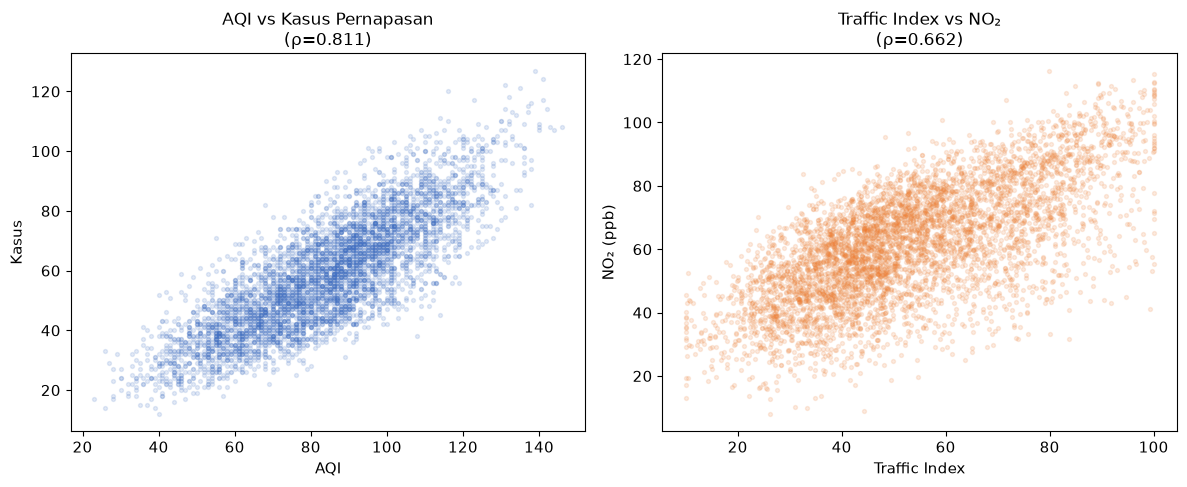

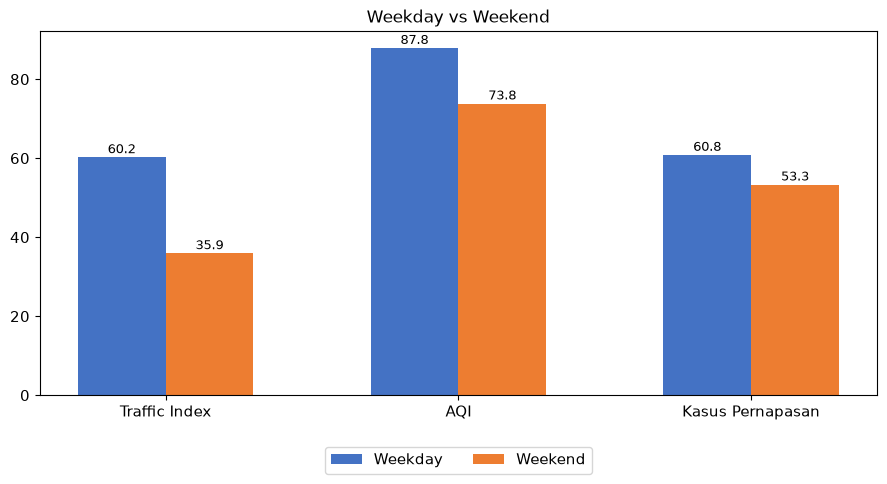

Semua gambar tersimpan di figures/


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({'font.size':11,'axes.titlesize':12})

# --- gambar_2 ---
kota_s = kota_tbl.sort_values('AQI', ascending=True)
fig, ax = plt.subplots(figsize=(9,6))
y = np.arange(len(kota_s)); h = 0.35
ax.barh(y-h/2, kota_s['AQI'],   h, label='Rerata AQI',              color='#4472C4')
ax.barh(y+h/2, kota_s['Kasus'], h, label='Rerata Kasus Pernapasan', color='#ED7D31')
ax.axvline(100, color='red', linestyle='--', lw=1.4, label='Ambang AQI 100')
ax.set_yticks(y); ax.set_yticklabels(kota_s.index)
ax.set_xlabel('Nilai Rerata'); ax.set_title('Rerata AQI dan Kasus Pernapasan per Kota')
ax.legend(loc='upper center', bbox_to_anchor=(0.5,-0.13), ncol=3)
plt.tight_layout(); plt.savefig('figures/gambar_2_antar_kota.png', dpi=200, bbox_inches='tight'); plt.show()

# --- gambar_3 ---
zona_p = zona_tbl[['AQI','PM25','NO2','Kasus']]
fig, ax = plt.subplots(figsize=(9,5))
y = np.arange(len(zona_p)); bh = 0.18
for i,(col,clr) in enumerate(zip(zona_p.columns,['#4472C4','#ED7D31','#A9D18E','#FF6666'])):
    ax.barh(y+(i-2)*bh+bh/2, zona_p[col], bh, label=col, color=clr)
ax.set_yticks(y); ax.set_yticklabels(zona_p.index)
ax.set_xlabel('Nilai Rerata'); ax.set_title('Profil per Tipe Zona')
ax.legend(loc='upper center', bbox_to_anchor=(0.5,-0.13), ncol=4)
plt.tight_layout(); plt.savefig('figures/gambar_3_zona.png', dpi=200, bbox_inches='tight'); plt.show()

# --- gambar_4 ---
fig, axes = plt.subplots(3,1, figsize=(10,9), sharex=True)
hx = jam_tbl.index
axes[0].plot(hx, jam_tbl['traffic'], marker='o', color='#4472C4')
axes[0].set_ylabel('Traffic Index'); axes[0].set_title('Traffic Index per Jam')
axes[1].plot(hx, jam_tbl['AQI'],    marker='o', color='#ED7D31')
axes[1].set_ylabel('AQI');          axes[1].set_title('AQI per Jam')
axes[2].plot(hx, jam_tbl['kasus'],  marker='o', color='#A9D18E')
axes[2].set_ylabel('Kasus');        axes[2].set_title('Kasus Pernapasan per Jam')
axes[2].set_xlabel('Jam'); axes[2].xaxis.set_major_locator(mticker.MultipleLocator(3))
plt.tight_layout(); plt.savefig('figures/gambar_4_jam.png', dpi=200, bbox_inches='tight'); plt.show()

# --- gambar_5 ---
fig, axes = plt.subplots(1,3, figsize=(12,5))
for ax, (col, lbl) in zip(axes,[('PM25','PM2.5 (µg/m³)'),('AQI','AQI'),('kasus','Kasus')]):
    vals = hujan_tbl[col]
    bars = ax.bar(hujan_tbl.index, vals, color=['#E07B54','#5B9BD5'])
    for bar,v in zip(bars,vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5, f'{v:.2f}', ha='center', va='bottom')
    ax.set_title(lbl)
plt.suptitle('Hujan vs Tidak Hujan', y=1.02)
plt.tight_layout(); plt.savefig('figures/gambar_5_hujan.png', dpi=200, bbox_inches='tight'); plt.show()

# --- gambar_6 ---
rho6_ac, _ = stats.spearmanr(df['aqi_score'],     df['respiratory_cases'])
rho6_tn, _ = stats.spearmanr(df['traffic_index'],  df['no2_ppb'])
fig, axes = plt.subplots(1,2, figsize=(12,5))
axes[0].scatter(df['aqi_score'],    df['respiratory_cases'], alpha=0.15, s=8, color='#4472C4')
axes[0].set_xlabel('AQI'); axes[0].set_ylabel('Kasus')
axes[0].set_title(f'AQI vs Kasus Pernapasan\n(ρ={rho6_ac:.3f})')
axes[1].scatter(df['traffic_index'], df['no2_ppb'], alpha=0.15, s=8, color='#ED7D31')
axes[1].set_xlabel('Traffic Index'); axes[1].set_ylabel('NO₂ (ppb)')
axes[1].set_title(f'Traffic Index vs NO₂\n(ρ={rho6_tn:.3f})')
plt.tight_layout(); plt.savefig('figures/gambar_6_hubungan.png', dpi=200, bbox_inches='tight'); plt.show()

# --- gambar_7 ---
fig, ax = plt.subplots(figsize=(9,5))
x = np.arange(3); w = 0.3
v_wd = [wd_we.loc['Weekday',m] for m in ['traffic','AQI','kasus']]
v_we = [wd_we.loc['Weekend',m] for m in ['traffic','AQI','kasus']]
b1 = ax.bar(x-w/2, v_wd, w, label='Weekday', color='#4472C4')
b2 = ax.bar(x+w/2, v_we, w, label='Weekend', color='#ED7D31')
for bar in list(b1)+list(b2):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(['Traffic Index','AQI','Kasus Pernapasan'])
ax.set_title('Weekday vs Weekend')
ax.legend(loc='upper center', bbox_to_anchor=(0.5,-0.12), ncol=2)
plt.tight_layout(); plt.savefig('figures/gambar_7_weekday_weekend.png', dpi=200, bbox_inches='tight'); plt.show()
print("Semua gambar tersimpan di figures/")

## 10. Ringkasan Angka & Assert
Semua nilai dicocokkan dengan nilai acuan proposal (toleransi 0,01; korelasi 0,001).

In [11]:
from scipy import stats as _st2
TOL = 0.01; TOL_R = 0.001
failures = []

def chk(label, actual, expected, tol=TOL):
    diff = abs(actual - expected)
    ok = diff <= tol
    tag = "LOLOS" if ok else "GAGAL"
    if not ok: failures.append((label, actual, expected, diff))
    print(f"[{tag}] {label}: {actual:.4f}  acuan={expected}  Δ={diff:.4f}")

pct_rv = df["risk_aqi"].mean()*100
n_rv   = int(df["risk_aqi"].sum())
safe_m  = df[~df["risk_aqi"]]["respiratory_cases"].mean()
risky_m = df[ df["risk_aqi"]]["respiratory_cases"].mean()

chk("% AQI>100",         pct_rv, 21.42)
chk("n AQI>100",         n_rv,   1071, tol=0)
chk("kasus AQI aman",    safe_m, 52.82)
chk("kasus AQI berisiko",risky_m,79.91)
chk("n Moderate",(df["air_quality_status"]=="Moderate").sum(),3639,tol=0)
chk("n USG",     (df["air_quality_status"]=="Unhealthy for Sensitive Groups").sum(),1071,tol=0)
chk("n Good",    (df["air_quality_status"]=="Good").sum(),290,tol=0)
chk("Jakarta Pusat AQI",  kota_tbl.loc["Jakarta Pusat","AQI"],  97.23)
chk("Jakarta Pusat kasus",kota_tbl.loc["Jakarta Pusat","Kasus"],83.02)
chk("Makassar AQI",       kota_tbl.loc["Makassar","AQI"],       62.39)
chk("Makassar kasus",     kota_tbl.loc["Makassar","Kasus"],     35.02)
chk("Bekasi PM2.5",       kota_tbl.loc["Bekasi","PM25"],        68.26)
chk("Tangerang PM2.5",    kota_tbl.loc["Tangerang","PM25"],     64.30)
chk("Bandung AQI",        kota_tbl.loc["Bandung","AQI"],        91.63)
chk("Bandung kasus",      kota_tbl.loc["Bandung","Kasus"],      71.39)
chk("Medan AQI",          kota_tbl.loc["Medan","AQI"],          90.22)
chk("Medan kasus",        kota_tbl.loc["Medan","Kasus"],        59.77)
chk("Zona Traffic NO2",      zona_tbl.loc["Traffic","NO2"],       73.03)
chk("Zona Traffic AQI",      zona_tbl.loc["Traffic","AQI"],       93.03)
chk("Zona Traffic kasus",    zona_tbl.loc["Traffic","Kasus"],     71.39)
chk("Zona Industrial PM2.5", zona_tbl.loc["Industrial","PM25"],   62.54)
chk("Zona Residential AQI",  zona_tbl.loc["Residential","AQI"],   70.00)
chk("Zona Residential kasus",zona_tbl.loc["Residential","Kasus"], 41.98)
chk("Jam 06 traffic",jam_tbl.loc[6,"traffic"],  65.57)
chk("Jam 09 traffic",jam_tbl.loc[9,"traffic"],  65.70)
chk("Jam 18 traffic",jam_tbl.loc[18,"traffic"], 64.91)
chk("Jam 06 AQI",   jam_tbl.loc[6,"AQI"],       91.08)
chk("Jam 09 AQI",   jam_tbl.loc[9,"AQI"],       91.09)
chk("Jam 18 AQI",   jam_tbl.loc[18,"AQI"],      90.82)
chk("Jam 06 kasus", jam_tbl.loc[6,"kasus"],     63.07)
chk("Jam 18 kasus", jam_tbl.loc[18,"kasus"],    63.30)
chk("Jam 21 AQI",   jam_tbl.loc[21,"AQI"],      80.07)
chk("Hujan PM2.5 kering",hujan_tbl.loc["Tidak Hujan","PM25"],60.54)
chk("Hujan PM2.5 basah", hujan_tbl.loc["Hujan","PM25"],      44.61)
chk("Hujan AQI kering",  hujan_tbl.loc["Tidak Hujan","AQI"], 87.69)
chk("Hujan AQI basah",   hujan_tbl.loc["Hujan","AQI"],       65.30)
chk("Hujan kasus kering",hujan_tbl.loc["Tidak Hujan","kasus"],60.75)
chk("Hujan kasus basah", hujan_tbl.loc["Hujan","kasus"],      48.52)
chk("rho rainfall-PM2.5",rho_rain_pm25,-0.405,tol=TOL_R)
chk("rho rainfall-AQI",  rho_rain_aqi, -0.413,tol=TOL_R)
chk("rho AQI-kasus",    rho_dict["aqi_score"],    0.811,tol=TOL_R)
chk("rho NO2-kasus",    rho_dict["no2_ppb"],      0.779,tol=TOL_R)
chk("rho PM2.5-kasus",  rho_dict["pm25_ug_m3"],   0.719,tol=TOL_R)
chk("rho traffic-kasus",rho_dict["traffic_index"],0.464,tol=TOL_R)
chk("rho traffic-NO2",  rho_tr_no2,               0.662,tol=TOL_R)
chk("rho suhu-AQI",    rho_temp_aqi, -0.02, tol=TOL_R)
chk("rho suhu-kasus",  rho_temp_cas, -0.10, tol=TOL_R)
chk("Weekday traffic",wd_we.loc["Weekday","traffic"],60.20)
chk("Weekend traffic",wd_we.loc["Weekend","traffic"],35.88)
chk("Weekday PM2.5",  wd_we.loc["Weekday","PM25"],  60.22)
chk("Weekend PM2.5",  wd_we.loc["Weekend","PM25"],  51.71)
chk("Weekday NO2",    wd_we.loc["Weekday","NO2"],   65.53)
chk("Weekend NO2",    wd_we.loc["Weekend","NO2"],   52.08)
chk("Weekday AQI",    wd_we.loc["Weekday","AQI"],   87.85)
chk("Weekend AQI",    wd_we.loc["Weekend","AQI"],   73.79)
chk("Weekday kasus",  wd_we.loc["Weekday","kasus"], 60.79)
chk("Weekend kasus",  wd_we.loc["Weekend","kasus"], 53.27)
chk("Weekday %AQI>100",wd_we.loc["Weekday","pct_AQI_risk"],28.43)
chk("Weekend %AQI>100",wd_we.loc["Weekend","pct_AQI_risk"], 4.10)
chk("Lag 0",lag_res[0],0.811,tol=TOL_R)
chk("Lag 1",lag_res[1],0.422,tol=TOL_R)
chk("Lag 2",lag_res[2],0.384,tol=TOL_R)
chk("Lag 4",lag_res[4],0.428,tol=TOL_R)

print()
if failures:
    print(f"TOTAL GAGAL: {len(failures)}")
    for lbl,act,exp,d in failures:
        print(f"  ⚠ {lbl}: aktual={act:.4f}  acuan={exp}  Δ={d:.4f}")
else:
    print("SEMUA ASSERT LOLOS ✓")

[LOLOS] % AQI>100: 21.4200  acuan=21.42  Δ=0.0000
[LOLOS] n AQI>100: 1071.0000  acuan=1071  Δ=0.0000
[LOLOS] kasus AQI aman: 52.8213  acuan=52.82  Δ=0.0013
[LOLOS] kasus AQI berisiko: 79.9057  acuan=79.91  Δ=0.0043
[LOLOS] n Moderate: 3639.0000  acuan=3639  Δ=0.0000
[LOLOS] n USG: 1071.0000  acuan=1071  Δ=0.0000
[LOLOS] n Good: 290.0000  acuan=290  Δ=0.0000
[LOLOS] Jakarta Pusat AQI: 97.2300  acuan=97.23  Δ=0.0000
[LOLOS] Jakarta Pusat kasus: 83.0200  acuan=83.02  Δ=0.0000
[LOLOS] Makassar AQI: 62.3900  acuan=62.39  Δ=0.0000
[LOLOS] Makassar kasus: 35.0200  acuan=35.02  Δ=0.0000
[LOLOS] Bekasi PM2.5: 68.2600  acuan=68.26  Δ=0.0000
[LOLOS] Tangerang PM2.5: 64.3000  acuan=64.3  Δ=0.0000
[LOLOS] Bandung AQI: 91.6300  acuan=91.63  Δ=0.0000
[LOLOS] Bandung kasus: 71.3900  acuan=71.39  Δ=0.0000
[LOLOS] Medan AQI: 90.2200  acuan=90.22  Δ=0.0000
[LOLOS] Medan kasus: 59.7700  acuan=59.77  Δ=0.0000
[LOLOS] Zona Traffic NO2: 73.0300  acuan=73.03  Δ=0.0000
[LOLOS] Zona Traffic AQI: 93.0300  acuan=